# Tracking Differentiator

A step in the reference signal asks the controller to move the plant *instantly*. ADRC will try, which results in large control signals that real actuators cannot deliver.

Han's **tracking differentiator** [1] solves this outside the control loop: it turns the reference signal $r$ into a smooth transient profile $v_1$ and its derivative $v_2$, with the acceleration of the profile limited to $r_0$. The controller then tracks $v_1$ instead of $r$. The controller itself, its observer and its disturbance rejection are unchanged.

The discrete tracking differentiator, eqs. (10) and (11) in [1], is

$$
\begin{aligned}
v_1(k+1) &= v_1(k) + h\, v_2(k) \\
v_2(k+1) &= v_2(k) + h\, \mathrm{fhan}\big(v_1(k) - r(k),\ v_2(k),\ r_0,\ h_0\big)
\end{aligned}
$$

where $\mathrm{fhan}$ is the discrete time-optimal control function, $h$ the sampling time, $r_0$ the acceleration limit and $h_0$ a filter factor ($h_0 = h$ for the time-optimal profile).

[1] J. Han, "From PID to Active Disturbance Rejection Control", IEEE Transactions on Industrial Electronics, vol. 56, no. 3, pp. 900-906, 2009.

In [1]:
%matplotlib inline

import numpy as np
import pyadrc
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [10, 7.5]

## The transient profile

A step from 0 to 1 with $r_0 = 10$. The profile accelerates at $r_0$, then decelerates at $r_0$ and arrives without overshoot after the time-optimal $2\sqrt{\Delta r / r_0} \approx 0.63$ s.

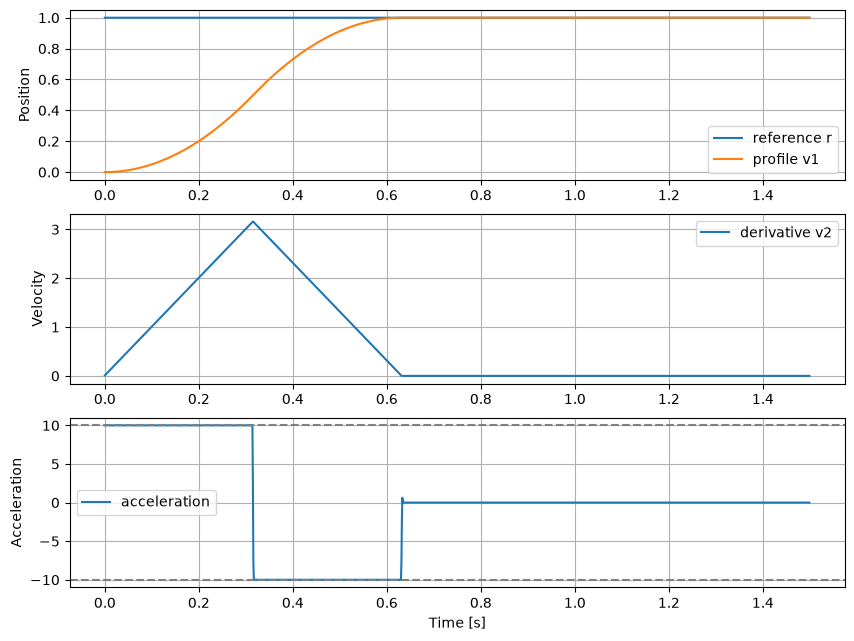

In [2]:
delta = 0.001
td = pyadrc.TrackingDifferentiator(delta, r0=10.)

t = np.arange(0, 1.5, delta)
v = np.array([td(1.) for _ in t])
v1, v2 = v[:, 0], v[:, 1]
acc = np.gradient(v2, delta)

plt.figure()
plt.subplot(3, 1, 1)
plt.plot(t, np.ones_like(t), label='reference r')
plt.plot(t, v1, label='profile v1')
plt.ylabel('Position')
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, v2, label='derivative v2')
plt.ylabel('Velocity')
plt.legend()
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, acc, label='acceleration')
plt.axhline(10, ls='--', c='gray')
plt.axhline(-10, ls='--', c='gray')
plt.ylabel('Acceleration')
plt.xlabel('Time [s]')
plt.legend()
plt.grid()

## Effect of $r_0$ and $h_0$

$r_0$ sets the speed of the profile, $h_0$ makes it smoother and slower (and filters noise on $r$).

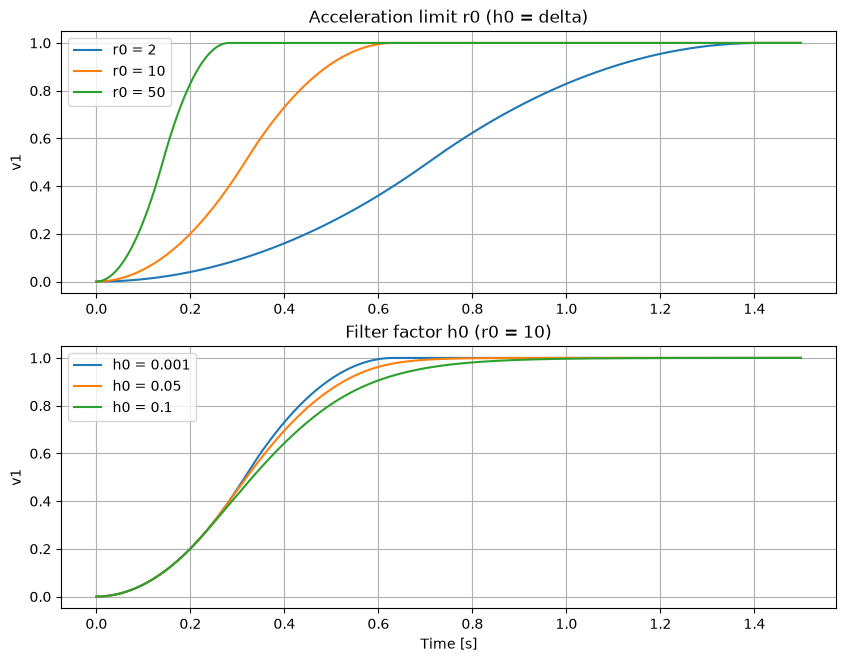

In [3]:
plt.figure()
plt.subplot(2, 1, 1)
for r0 in (2., 10., 50.):
    td = pyadrc.TrackingDifferentiator(delta, r0=r0)
    plt.plot(t, [td(1.)[0] for _ in t], label=f'r0 = {r0:g}')
plt.ylabel('v1')
plt.title('Acceleration limit r0 (h0 = delta)')
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
for h0 in (delta, 0.05, 0.1):
    td = pyadrc.TrackingDifferentiator(delta, r0=10., h0=h0)
    plt.plot(t, [td(1.)[0] for _ in t], label=f'h0 = {h0:g}')
plt.ylabel('v1')
plt.xlabel('Time [s]')
plt.title('Filter factor h0 (r0 = 10)')
plt.legend()
plt.grid()

## Altitude control of a quadcopter

The quadcopter and controller from the *Altitude Control of a Quadcopter* notebook: mass 28 g, hover thrust $mg \approx 0.27$ N, second-order ADRC with $\omega_{CL} = 12$ rad/s (settling time 0.5 s) and $k_{ESO} = 10$. The reference jumps to 0.5 m at $t = 0$ and to 1 m at $t = 1$ s.

The acceleration limit $r_0$ is chosen from what the actuator can deliver. Assuming the motors can produce about twice the hover thrust, the available upward acceleration is roughly $(2mg - mg)/m = g$, so we choose $r_0 = 5\ \mathrm{m/s^2}$, leaving margin for the controller to reject disturbances.

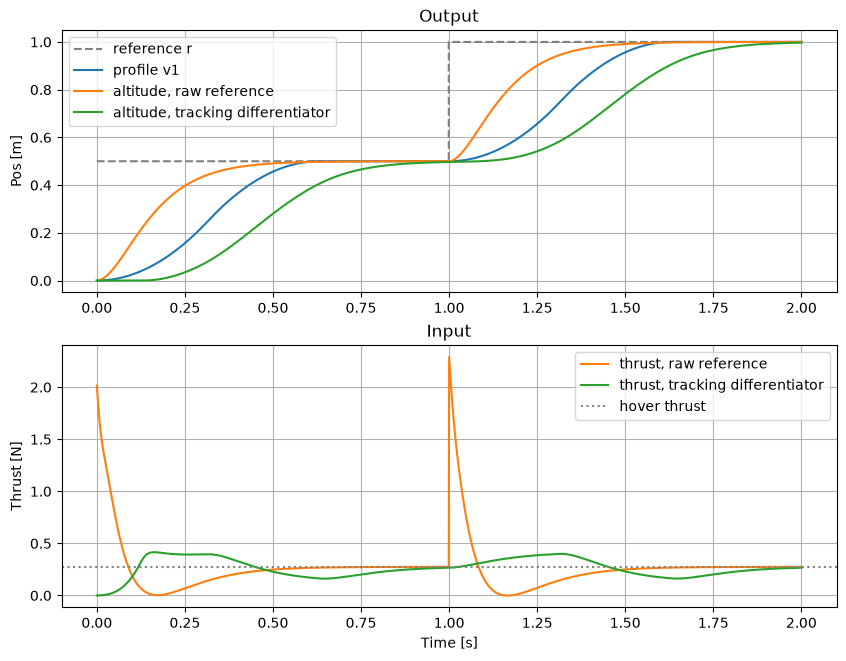

In [4]:
def simulate(r0=None, seconds=2.):
    quad = pyadrc.QuadAltitude(dt=delta, m=0.028, g=9.807)
    adrc = pyadrc.StateSpace(order=2, delta=delta, b0=1/0.028,
                             w_cl=12, k_eso=10)
    td = pyadrc.TrackingDifferentiator(delta, r0=r0) if r0 else None

    u = 0.
    _r, _ref, _y, _u = [], [], [], []
    for k in range(int(seconds / delta) + 1):
        r = 0.5 if k < 1000 else 1.
        ref = td(r)[0] if td else r  # shaped or raw reference

        y = quad(u)
        u = adrc(y, u, ref)

        _r.append(r)
        _ref.append(ref)
        _y.append(y)
        _u.append(u)

    return tuple(np.array(x) for x in (_r, _ref, _y, _u))


t = np.arange(0, 2 + delta / 2, delta)
r, _, y_raw, u_raw = simulate()
_, v1, y_td, u_td = simulate(r0=5.)

plt.figure()
plt.subplot(2, 1, 1)
plt.plot(t, r, ds='steps', c='gray', ls='--', label='reference r')
plt.plot(t, v1, c='C0', label='profile v1')
plt.plot(t, y_raw, c='C1', label='altitude, raw reference')
plt.plot(t, y_td, c='C2', label='altitude, tracking differentiator')
plt.ylabel('Pos [m]')
plt.title('Output')
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t, u_raw, c='C1', label='thrust, raw reference')
plt.plot(t, u_td, c='C2', label='thrust, tracking differentiator')
plt.axhline(0.028 * 9.807, ls=':', c='gray', label='hover thrust')
plt.ylabel('Thrust [N]')
plt.xlabel('Time [s]')
plt.title('Input')
plt.legend()
plt.grid()

In [5]:
for name, u in (('raw reference', u_raw),
                ('tracking differentiator', u_td)):
    print(f'{name:>24}: peak thrust {u.max():.2f} N '
          f'({u.max() / (0.028 * 9.807):.1f} x hover)')

           raw reference: peak thrust 2.29 N (8.3 x hover)
 tracking differentiator: peak thrust 0.42 N (1.5 x hover)


With the raw reference, ADRC demands a thrust peak of several times the hover thrust, which a small quadcopter cannot produce. With the tracking differentiator, the peak stays within what the motors can deliver, and there is still no overshoot.

The price is speed: the profile itself needs $2\sqrt{0.5/5} \approx 0.63$ s per step, and the controller follows it with a small delay. $r_0$ is the knob for this trade-off; choose it from the actuator limits rather than detuning the controller.